Shape: (452, 678)
Data type: uint8
Min intensity: 0
Max intensity: 245


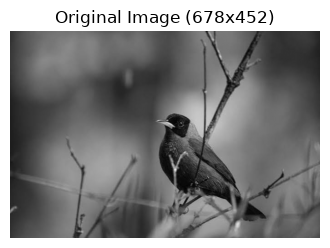

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load and validate grayscale image
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

assert img is not None, "Failed to load 'image.jpg'. Make sure it is in your project root."
assert img.ndim == 2, "Image is not 8-bit grayscale."
h, w = img.shape
assert h >= 300 and w >= 300, f"Image resolution ({w}x{h}) must be at least 300x300."

print(f"Shape: {img.shape}")
print(f"Data type: {img.dtype}")
print(f"Min intensity: {img.min()}")
print(f"Max intensity: {img.max()}")

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title(f"Original Image ({w}x{h})")
plt.axis('off')
plt.show()

Dry Run 1 (+40): [70, 120, 168, 220, 255]
Dry Run 1 (-40): [0, 40, 88, 140, 200]
Verification Passed: Vectorized and nested-loop implementations are identical.


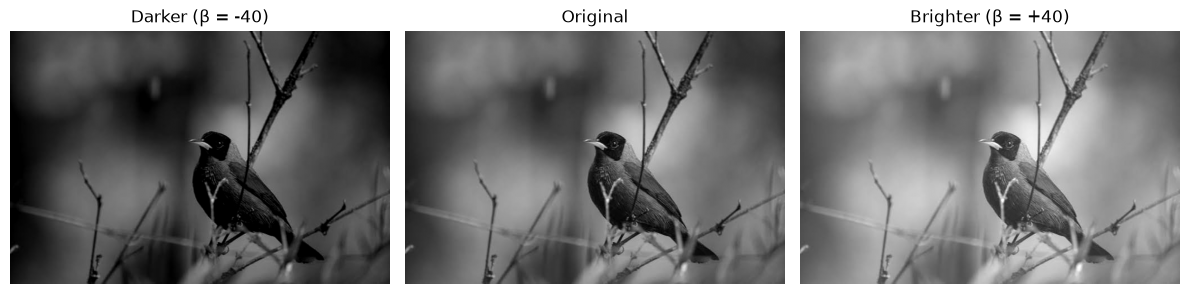

In [2]:
# Dry run verification
r_dry1 = np.array([30, 80, 128, 180, 240], dtype=np.int32)
plus40_dry = np.clip(r_dry1 + 40, 0, 255).astype(np.uint8)
minus40_dry = np.clip(r_dry1 - 40, 0, 255).astype(np.uint8)
print("Dry Run 1 (+40):", plus40_dry.tolist())
print("Dry Run 1 (-40):", minus40_dry.tolist())

# Full Image: Vectorized NumPy
img_int = img.astype(np.int32)
bright_np = np.clip(img_int + 40, 0, 255).astype(np.uint8)
dark_np = np.clip(img_int - 40, 0, 255).astype(np.uint8)

# Full Image: Nested loop verification (+40)
h, w = img.shape
bright_loop = np.zeros((h, w), dtype=np.uint8)
for i in range(h):
    for j in range(w):
        val = int(img[i, j]) + 40
        if val > 255:
            bright_loop[i, j] = 255
        elif val < 0:
            bright_loop[i, j] = 0
        else:
            bright_loop[i, j] = val

assert np.array_equal(bright_np, bright_loop), "NumPy and loop results do not match!"
print("Verification Passed: Vectorized and nested-loop implementations are identical.")

# Display Comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(dark_np, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Darker (β = -40)")
axes[1].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Original")
axes[2].imshow(bright_np, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Brighter (β = +40)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

Dry Run 2 Output: [45, 120, 192, 255, 255]


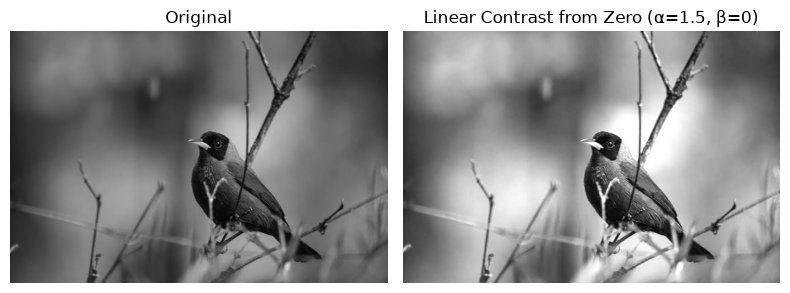

In [3]:
# Dry run verification
r_dry2 = np.array([30, 80, 128, 180, 240], dtype=np.float64)
s_dry2 = np.clip(1.5 * r_dry2, 0, 255).astype(np.uint8)
print("Dry Run 2 Output:", s_dry2.tolist())

# Full Image
contrast_zero = np.clip(1.5 * img.astype(np.float64), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(contrast_zero, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Linear Contrast from Zero (α=1.5, β=0)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

Dry Run 3 (α=1.5): [0, 56, 128, 206, 255]
Dry Run 3 (α=0.5): [79, 104, 128, 154, 184]


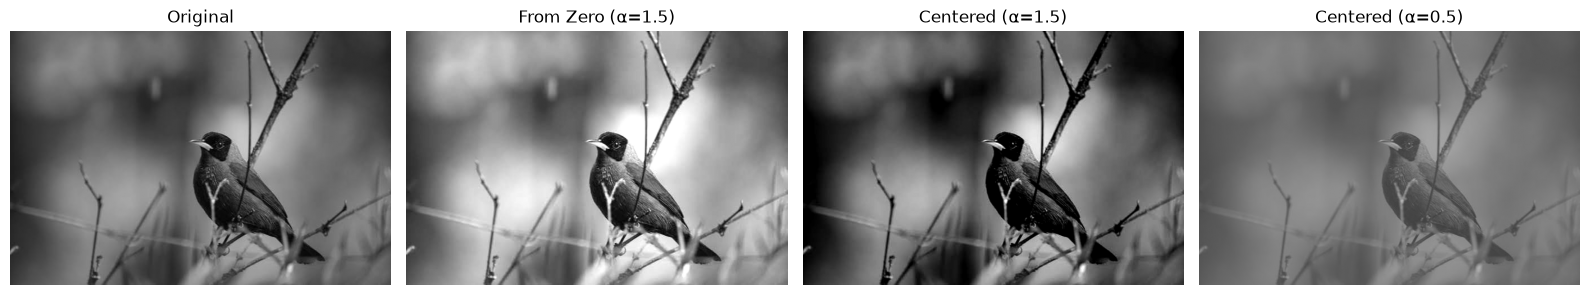

In [4]:
# Dry run verification
r_dry3 = np.array([30, 80, 128, 180, 240], dtype=np.float64)
c15_dry = np.clip((r_dry3 - 128.0) * 1.5 + 128.0, 0, 255).astype(np.uint8)
c05_dry = np.clip((r_dry3 - 128.0) * 0.5 + 128.0, 0, 255).astype(np.uint8)
print("Dry Run 3 (α=1.5):", c15_dry.tolist())
print("Dry Run 3 (α=0.5):", c05_dry.tolist())

# Task 2 reference image computed locally to avoid NameError
contrast_zero = np.clip(1.5 * img.astype(np.float64), 0, 255).astype(np.uint8)

# Task 3 full image transformations
img_f = img.astype(np.float64)
c_centered_high = np.clip((img_f - 128.0) * 1.5 + 128.0, 0, 255).astype(np.uint8)
c_centered_low = np.clip((img_f - 128.0) * 0.5 + 128.0, 0, 255).astype(np.uint8)

# 4-panel comparison plot
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(contrast_zero, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("From Zero (α=1.5)")
axes[2].imshow(c_centered_high, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Centered (α=1.5)")
axes[3].imshow(c_centered_low, cmap='gray', vmin=0, vmax=255)
axes[3].set_title("Centered (α=0.5)")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

Dry Run 4 Negative: [225, 175, 127, 75, 15]
Dry Run 4 Inverted Back: [30, 80, 128, 180, 240]


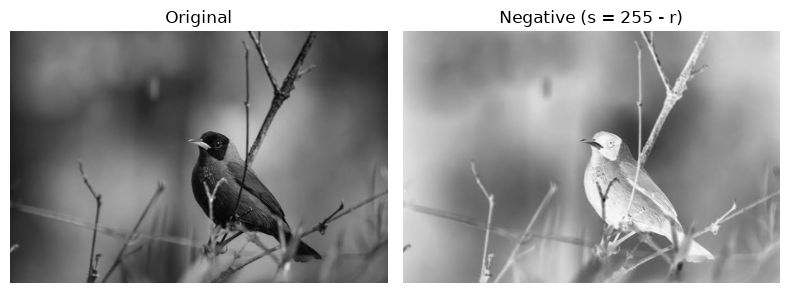

In [5]:
# Dry run verification
r_dry4 = np.array([30, 80, 128, 180, 240], dtype=np.int32)
neg_dry = 255 - r_dry4
double_neg_dry = 255 - neg_dry
print("Dry Run 4 Negative:", neg_dry.tolist())
print("Dry Run 4 Inverted Back:", double_neg_dry.tolist())
assert np.array_equal(r_dry4, double_neg_dry)

# Full Image
img_neg = 255 - img

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(img_neg, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Negative (s = 255 - r)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

Dry Run 5 (γ=0.5): [0, 127, 180, 221, 255]
Dry Run 5 (γ=2.0): [0, 16, 64, 144, 255]


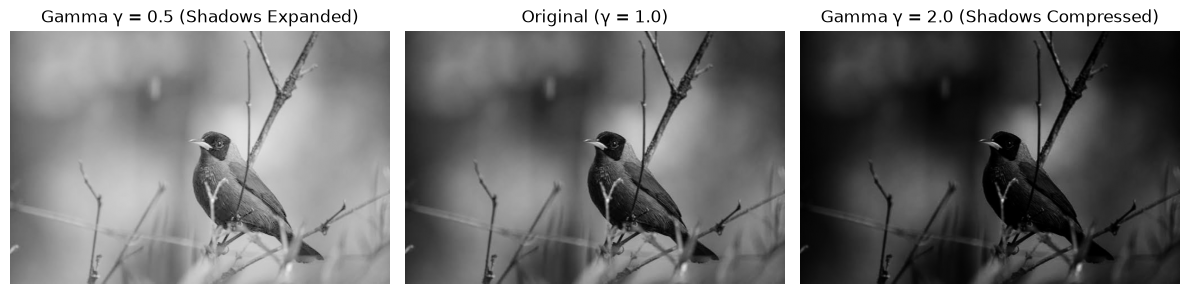

In [6]:
# Dry run verification
r_dry5 = np.array([0, 64, 128, 192, 255], dtype=np.float64)
g05_dry = np.trunc(255.0 * ((r_dry5 / 255.0) ** 0.5)).astype(np.uint8)
g20_dry = np.trunc(255.0 * ((r_dry5 / 255.0) ** 2.0)).astype(np.uint8)
print("Dry Run 5 (γ=0.5):", g05_dry.tolist())
print("Dry Run 5 (γ=2.0):", g20_dry.tolist())

# Full Image
img_norm = img.astype(np.float64) / 255.0
gamma_05 = np.trunc(255.0 * (img_norm ** 0.5)).astype(np.uint8)
gamma_20 = np.trunc(255.0 * (img_norm ** 2.0)).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(gamma_05, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Gamma γ = 0.5 (Shadows Expanded)")
axes[1].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Original (γ = 1.0)")
axes[2].imshow(gamma_20, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Gamma γ = 2.0 (Shadows Compressed)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

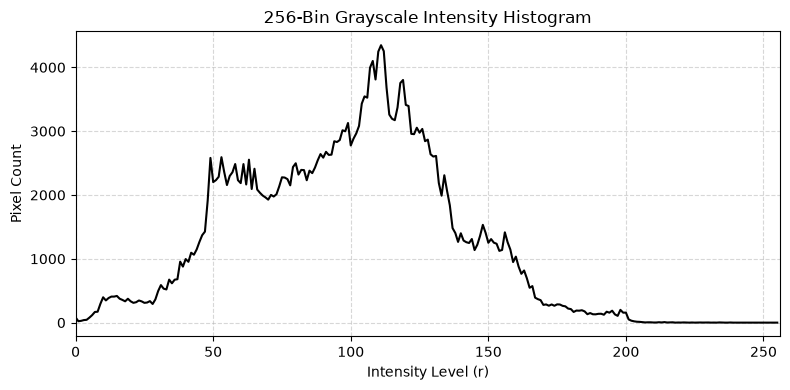

In [7]:
# Task 6: 256-bin histogram
hist = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(8, 4))
plt.plot(hist, color='black', linewidth=1.5)
plt.title("256-Bin Grayscale Intensity Histogram")
plt.xlabel("Intensity Level (r)")
plt.ylabel("Pixel Count")
plt.xlim([0, 256])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

OpenCV Dry Run Output:
 [0, 0, 128, 255]


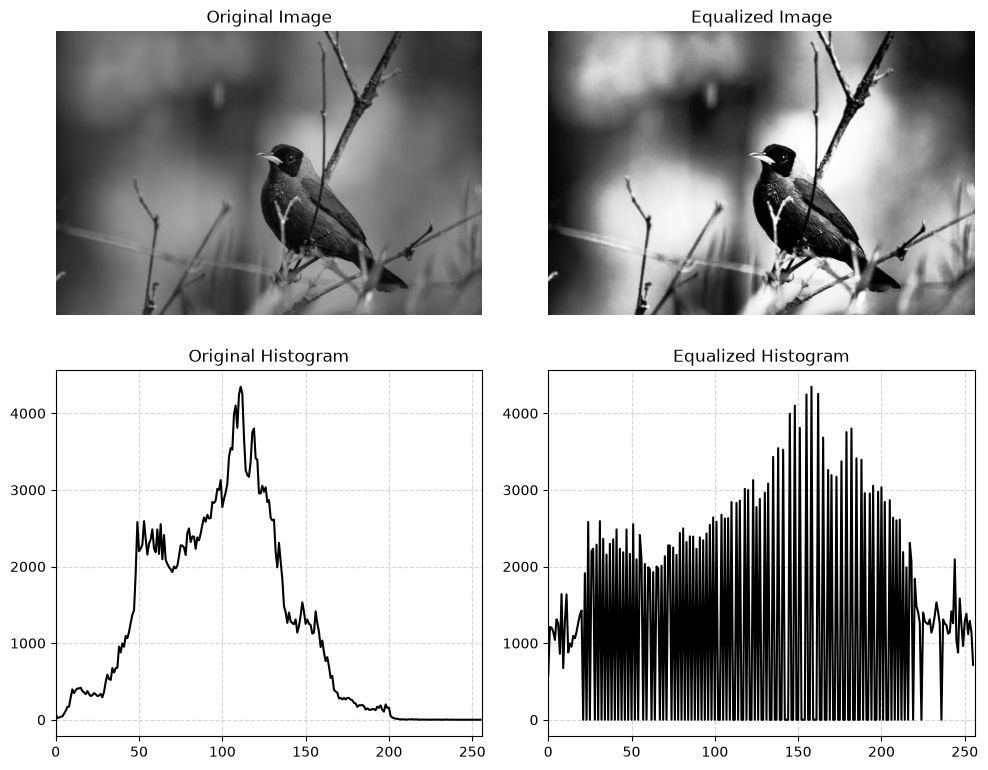

In [8]:
# Dry run verification with OpenCV
sample_dry7 = np.array([[50, 50], [100, 150]], dtype=np.uint8)
cv_eq_dry = cv2.equalizeHist(sample_dry7)
print("OpenCV Dry Run Output:\n", cv_eq_dry.flatten().tolist())

# Full Image
img_equalized = cv2.equalizeHist(img)
hist_eq = cv2.calcHist([img_equalized], [0], None, [256], [0, 256])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(img_equalized, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Equalized Image")

axes[1, 0].plot(hist, color='black')
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim([0, 256])
axes[1, 1].plot(hist_eq, color='black')
axes[1, 1].set_title("Equalized Histogram")
axes[1, 1].set_xlim([0, 256])

for ax in [axes[0, 0], axes[0, 1]]: ax.axis('off')
for ax in [axes[1, 0], axes[1, 1]]: ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

OpenCV Dry Run Output:
 [0, 0, 128, 255]


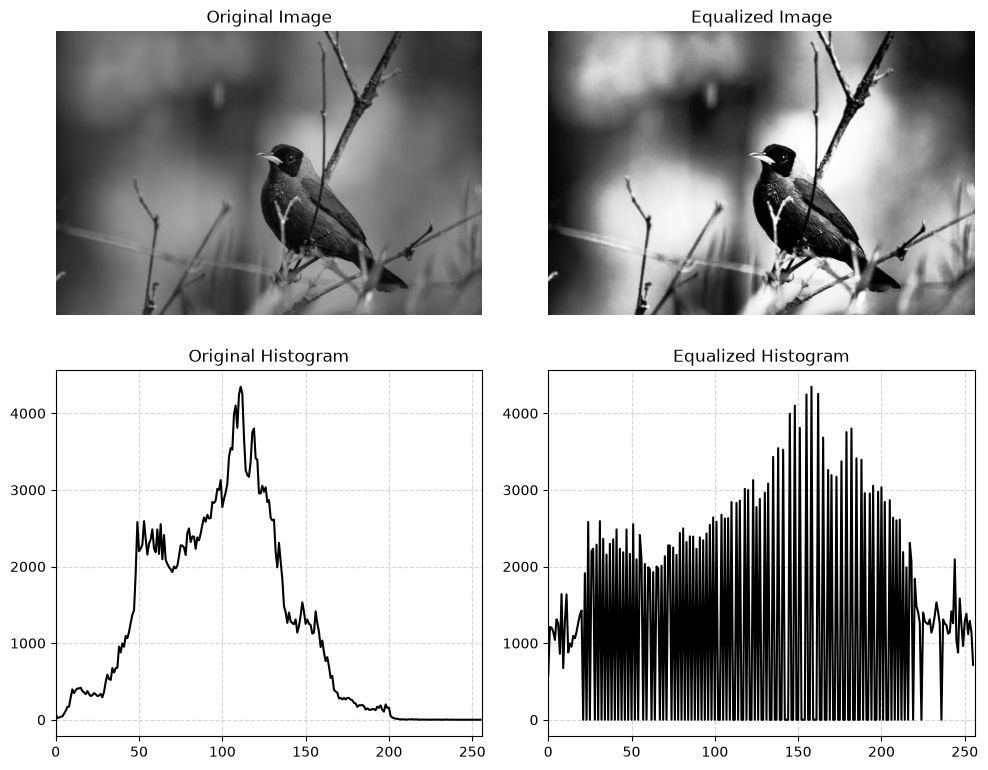

In [9]:
# Dry run verification with OpenCV
sample_dry7 = np.array([[50, 50], [100, 150]], dtype=np.uint8)
cv_eq_dry = cv2.equalizeHist(sample_dry7)
print("OpenCV Dry Run Output:\n", cv_eq_dry.flatten().tolist())

# Full Image
img_equalized = cv2.equalizeHist(img)
hist_eq = cv2.calcHist([img_equalized], [0], None, [256], [0, 256])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(img_equalized, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Equalized Image")

axes[1, 0].plot(hist, color='black')
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim([0, 256])
axes[1, 1].plot(hist_eq, color='black')
axes[1, 1].set_title("Equalized Histogram")
axes[1, 1].set_xlim([0, 256])

for ax in [axes[0, 0], axes[0, 1]]: ax.axis('off')
for ax in [axes[1, 0], axes[1, 1]]: ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

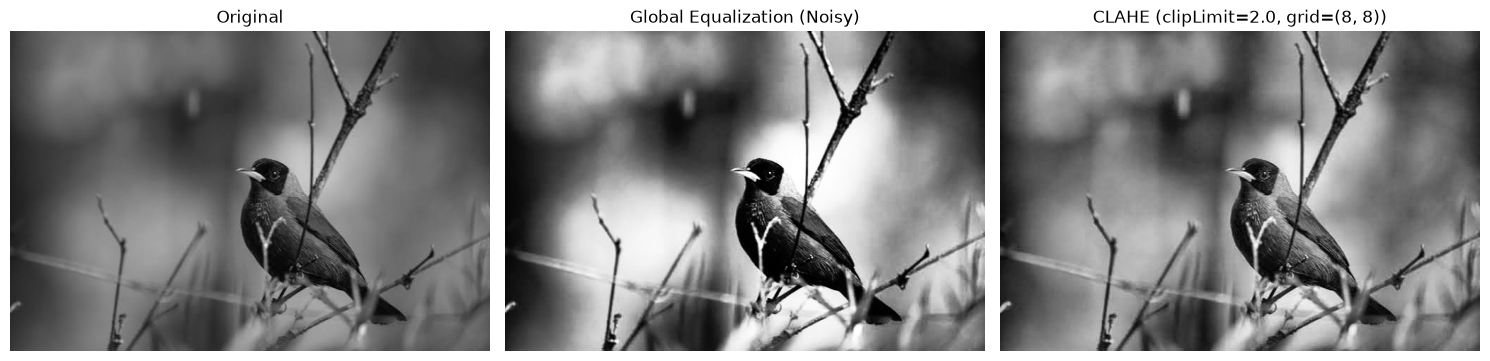

In [10]:
# Task 8: CLAHE implementation
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(img_equalized, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Global Equalization (Noisy)")
axes[2].imshow(img_clahe, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("CLAHE (clipLimit=2.0, grid=(8, 8))")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

Dry Run 9 (T=127): [[0, 0, 0, 255, 255, 255]]
Dry Run 9 (T=180): [[0, 0, 0, 0, 0, 255]]
Unique pixel values in binary image: [  0 255]


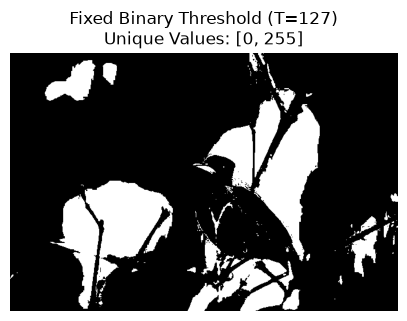

In [11]:
# Dry run verification
r_dry9 = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
_, t127_dry = cv2.threshold(r_dry9, 127, 255, cv2.THRESH_BINARY)
_, t180_dry = cv2.threshold(r_dry9, 180, 255, cv2.THRESH_BINARY)
print("Dry Run 9 (T=127):", t127_dry.tolist())
print("Dry Run 9 (T=180):", t180_dry.tolist())

# Full Image
_, bin_fixed = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
unique_vals = np.unique(bin_fixed)
print("Unique pixel values in binary image:", unique_vals)

plt.figure(figsize=(5, 5))
plt.imshow(bin_fixed, cmap='gray', vmin=0, vmax=255)
plt.title(f"Fixed Binary Threshold (T=127)\nUnique Values: {unique_vals.tolist()}")
plt.axis('off')
plt.show()

Otsu Dry Run Threshold: 1.0
Otsu Dry Run Mask:
 [0, 0, 255, 255]
Computed Otsu Threshold on Image: 94.0


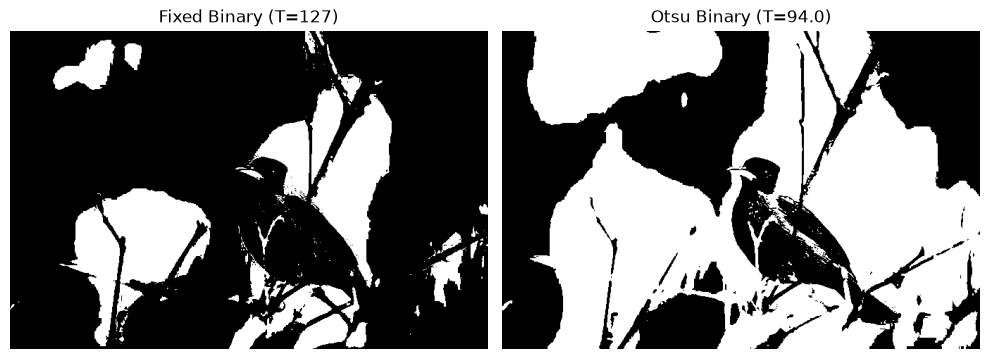

In [12]:
# Dry run verification with OpenCV
sample_dry10 = np.array([[0, 1], [4, 5]], dtype=np.uint8)
otsu_thresh_dry, otsu_mask_dry = cv2.threshold(sample_dry10, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Otsu Dry Run Threshold: {otsu_thresh_dry}")
print("Otsu Dry Run Mask:\n", otsu_mask_dry.flatten().tolist())

# Full Image
otsu_thresh, bin_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Computed Otsu Threshold on Image: {otsu_thresh}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(bin_fixed, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Fixed Binary (T=127)")
axes[1].imshow(bin_otsu, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Otsu Binary (T={otsu_thresh:.1f})")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

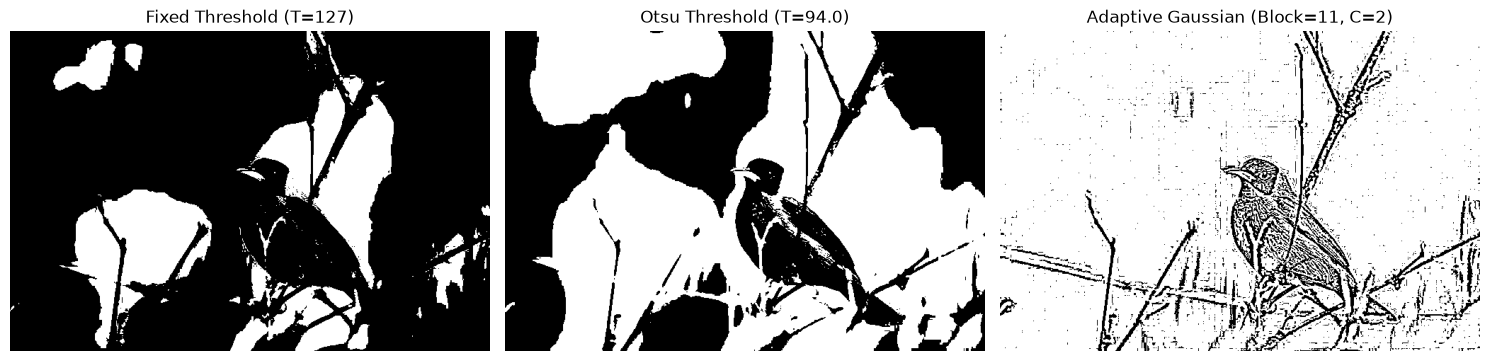

In [13]:
# Full Image: Adaptive Gaussian Thresholding
bin_adaptive = cv2.adaptiveThreshold(
    img, 
    255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY, 
    11, 
    2
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(bin_fixed, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Fixed Threshold (T=127)")
axes[1].imshow(bin_otsu, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Otsu Threshold (T={otsu_thresh:.1f})")
axes[2].imshow(bin_adaptive, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Adaptive Gaussian (Block=11, C=2)")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()